Introduction : Time Series EDA Assignment

The objective of this analysis is to study Microsoft's (MSFT) stock price
from 2017 to 2022 using Python, Pandas and time series analysis.

The analysis aims to:

1. Retrieve Microsoft's historical stock data.
2. Perform basic data exploration and cleaning.
3. Analyze the stock price as a time series.
4. Find the maximum stock price between 2017 and 2022.
5. Identify the date on which the highest price occurred.
6. Identify the date on which the lowest price occurred.
7. Visualize the stock price trend over time.

In [1]:
!pip install yfinance pandas_datareader matplotlib seaborn

IMPORT LIBRARIES

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

from pandas_datareader import data as pdr

plt.style.use("seaborn-v0_8")

In [3]:
start = "2017-01-01"
end = "2023-01-01"

msft = yf.download(
    "MSFT",
    start=start,
    end=end,
    auto_adjust=False
)

msft.head()

[*********************100%***********************]  1 of 1 completed


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,MSFT,MSFT,MSFT,MSFT,MSFT,MSFT
Date,,,,,,
2017-01-03,56.049706,62.580002,62.840000,62.130001,62.790001,20694100
2017-01-04,55.798935,62.299999,62.750000,62.119999,62.480000,21340000
2017-01-05,55.798935,62.299999,62.660000,62.029999,62.189999,24876000
2017-01-06,56.282574,62.840000,63.150002,62.040001,62.299999,19922900
2017-01-09,56.103455,62.639999,63.080002,62.540001,62.759998,20382700


In [4]:
msft.shape

(1510, 6)

In [5]:
print("First 5 rows:")
display(msft.head())

print("Last 5 rows:")
display(msft.tail())

First 5 rows:


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,MSFT,MSFT,MSFT,MSFT,MSFT,MSFT
Date,,,,,,
2017-01-03,56.049706,62.580002,62.840000,62.130001,62.790001,20694100
2017-01-04,55.798935,62.299999,62.750000,62.119999,62.480000,21340000
2017-01-05,55.798935,62.299999,62.660000,62.029999,62.189999,24876000
2017-01-06,56.282574,62.840000,63.150002,62.040001,62.299999,19922900
2017-01-09,56.103455,62.639999,63.080002,62.540001,62.759998,20382700


Last 5 rows:


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,MSFT,MSFT,MSFT,MSFT,MSFT,MSFT
Date,,,,,,
2022-12-23,232.121750,238.729996,238.869995,233.940002,236.110001,21207000
2022-12-27,230.400787,236.960007,238.929993,235.830002,238.699997,16688600
2022-12-28,228.038025,234.529999,239.720001,234.169998,236.889999,17457100
2022-12-29,234.338669,241.009995,241.919998,235.649994,235.649994,19770700
2022-12-30,233.181625,239.820007,239.960007,236.660004,238.210007,21938500


In [6]:
msft.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1510 entries, 2017-01-03 to 2022-12-30
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   (Adj Close, MSFT)  1510 non-null   float64
 1   (Close, MSFT)      1510 non-null   float64
 2   (High, MSFT)       1510 non-null   float64
 3   (Low, MSFT)        1510 non-null   float64
 4   (Open, MSFT)       1510 non-null   float64
 5   (Volume, MSFT)     1510 non-null   int64  
dtypes: float64(5), int64(1)
memory usage: 82.6 KB


In [7]:
msft.describe()

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,MSFT,MSFT,MSFT,MSFT,MSFT,MSFT
count,1510.000000,1510.000000,1510.000000,1510.000000,1510.000000,1.510000e+03
mean,164.989679,173.612358,175.349007,171.702099,173.581199,2.892333e+07
std,80.550488,81.912107,82.826673,80.919448,81.908529,1.255386e+07
min,55.798935,62.299999,62.660000,61.950001,62.189999,7.425600e+06
25%,93.620855,101.145000,101.964998,99.769999,101.177502,2.086662e+07
50%,145.713547,153.730003,155.595001,151.084999,152.215004,2.577220e+07
75%,237.066666,245.157497,247.794998,242.857494,244.965000,3.320730e+07
max,330.515533,343.109985,349.670013,342.200012,344.619995,1.112421e+08


In [8]:
msft.columns = msft.columns.get_level_values(0)

In [9]:
msft.head()

Price,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2017-01-03,56.049706,62.580002,62.840000,62.130001,62.790001,20694100
2017-01-04,55.798935,62.299999,62.750000,62.119999,62.480000,21340000
2017-01-05,55.798935,62.299999,62.660000,62.029999,62.189999,24876000
2017-01-06,56.282574,62.840000,63.150002,62.040001,62.299999,19922900
2017-01-09,56.103455,62.639999,63.080002,62.540001,62.759998,20382700


In [10]:
msft.index

DatetimeIndex(['2017-01-03', '2017-01-04', '2017-01-05', '2017-01-06',
               '2017-01-09', '2017-01-10', '2017-01-11', '2017-01-12',
               '2017-01-13', '2017-01-17',
               ...
               '2022-12-16', '2022-12-19', '2022-12-20', '2022-12-21',
               '2022-12-22', '2022-12-23', '2022-12-27', '2022-12-28',
               '2022-12-29', '2022-12-30'],
              dtype='datetime64[ns]', name='Date', length=1510, freq=None)

In [11]:
msft.isnull().sum()

,0
Price,
Adj Close,0
Close,0
High,0
Low,0
Open,0
Volume,0


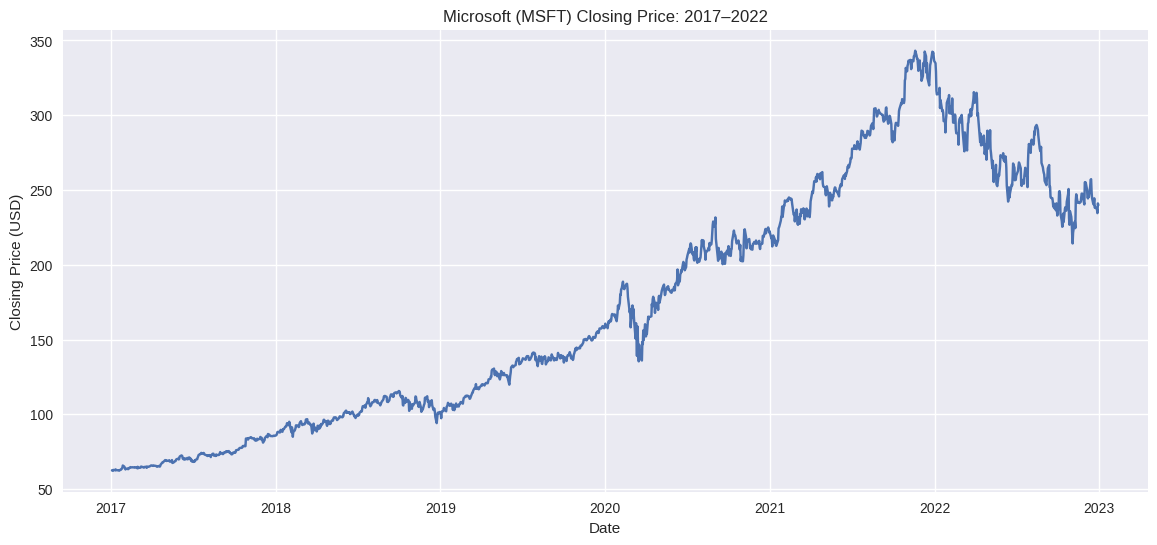

In [12]:
plt.figure(figsize=(14, 6))

plt.plot(msft.index, msft["Close"])

plt.title("Microsoft (MSFT) Closing Price: 2017–2022")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.grid(True)

plt.show()

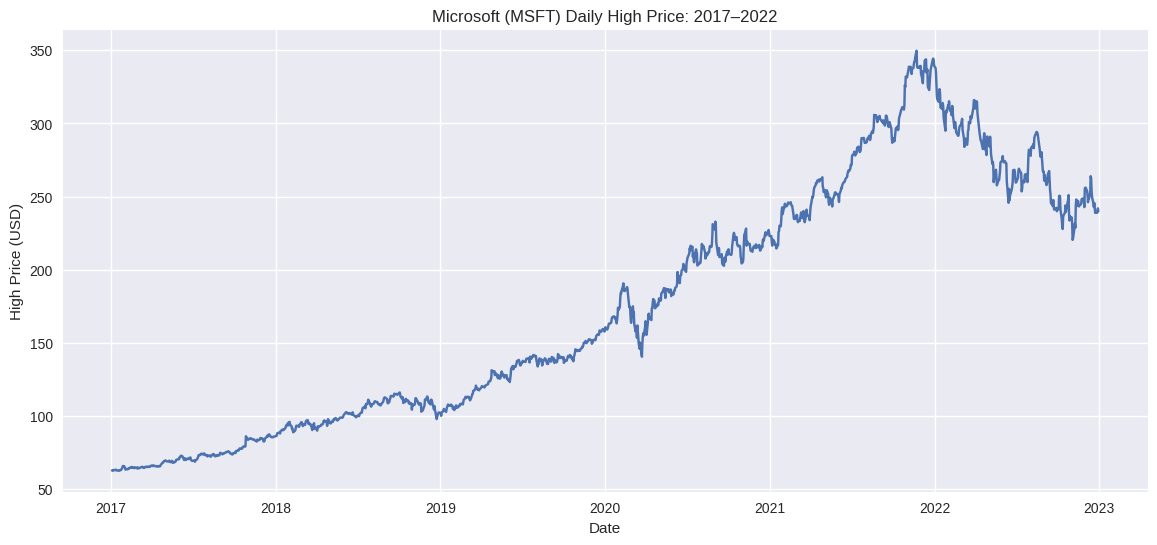

In [13]:
plt.figure(figsize=(14, 6))

plt.plot(msft.index, msft["High"])

plt.title("Microsoft (MSFT) Daily High Price: 2017–2022")
plt.xlabel("Date")
plt.ylabel("High Price (USD)")
plt.grid(True)

plt.show()

In [14]:
max_price = msft["High"].max()

print("Maximum share price from 2017 to 2022:", max_price)

Maximum share price from 2017 to 2022: 349.6700134277344


In [15]:
highest_date = msft["High"].idxmax()

print("Date of highest stock price:", highest_date)
print("Highest stock price:", msft.loc[highest_date, "High"])

Date of highest stock price: 2021-11-22 00:00:00
Highest stock price: 349.6700134277344


In [16]:
lowest_price = msft["Low"].min()

lowest_date = msft["Low"].idxmin()

print("Lowest stock price:", lowest_price)
print("Date of lowest stock price:", lowest_date)

Lowest stock price: 61.95000076293945
Date of lowest stock price: 2017-01-12 00:00:00


In [17]:
summary = pd.DataFrame({
    "Metric": [
        "Maximum Price",
        "Date of Highest Price",
        "Minimum Price",
        "Date of Lowest Price"
    ],
    "Value": [
        msft["High"].max(),
        msft["High"].idxmax(),
        msft["Low"].min(),
        msft["Low"].idxmin()
    ]
})

summary

,Metric,Value
0,Maximum Price,349.670013
1,Date of Highest Price,2021-11-22 00:00:00
2,Minimum Price,61.950001
3,Date of Lowest Price,2017-01-12 00:00:00


In [18]:
highest_row = msft.loc[[msft["High"].idxmax()]]

highest_row

Price,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2021-11-22,327.355865,339.829987,349.670013,339.549988,344.619995,31031100


In [19]:
yearly = msft.resample("YE").agg({
    "Open": "first",
    "High": "max",
    "Low": "min",
    "Close": "last",
    "Volume": "mean"
})

yearly

Price,Open,High,Low,Close,Volume
Date,,,,,
2017-12-31,62.790001,87.500000,61.950001,85.540001,2.243617e+07
2018-12-31,86.129997,116.180000,83.830002,101.570000,3.159019e+07
2019-12-31,99.550003,159.550003,97.199997,157.699997,2.458099e+07
2020-12-31,158.779999,232.860001,132.520004,222.419998,3.765959e+07
2021-12-31,222.529999,349.670013,211.940002,336.320007,2.601301e+07
2022-12-31,335.350006,338.000000,213.429993,239.820007,3.121932e+07


In [20]:
yearly_high = msft["High"].resample("YE").max()

yearly_high

,High
Date,
2017-12-31,87.500000
2018-12-31,116.180000
2019-12-31,159.550003
2020-12-31,232.860001
2021-12-31,349.670013
2022-12-31,338.000000


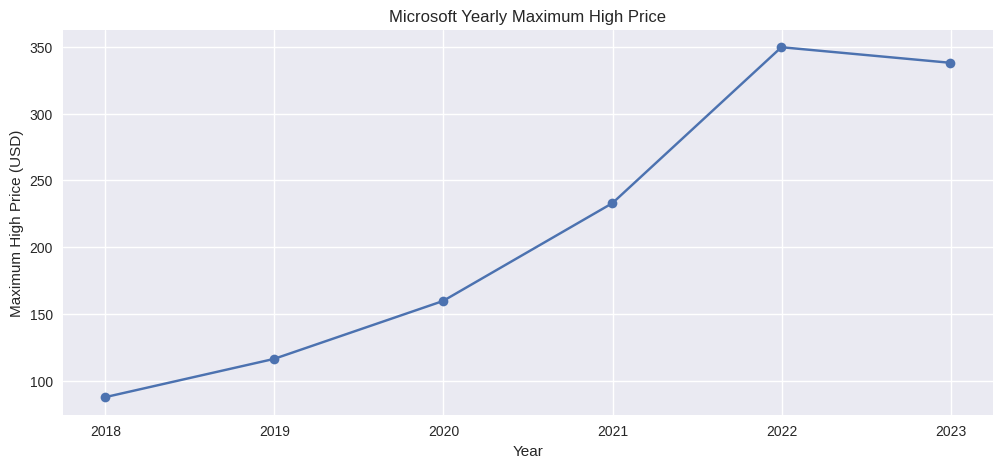

In [21]:
plt.figure(figsize=(12, 5))

plt.plot(yearly_high.index, yearly_high.values, marker="o")

plt.title("Microsoft Yearly Maximum High Price")
plt.xlabel("Year")
plt.ylabel("Maximum High Price (USD)")
plt.grid(True)

plt.show()

In [22]:
monthly_close = msft["Close"].resample("ME").mean()

monthly_close.head()

,Close
Date,
2017-01-31,63.192000
2017-02-28,64.113684
2017-03-31,64.841305
2017-04-30,66.171579
2017-05-31,68.917273


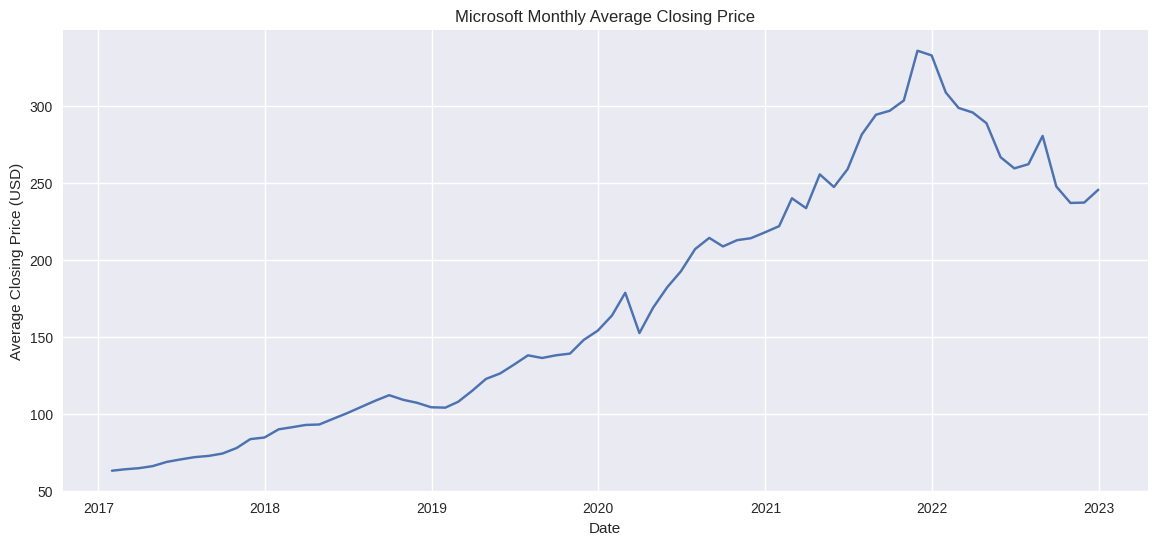

In [23]:
plt.figure(figsize=(14, 6))

plt.plot(monthly_close.index, monthly_close.values)

plt.title("Microsoft Monthly Average Closing Price")
plt.xlabel("Date")
plt.ylabel("Average Closing Price (USD)")
plt.grid(True)

plt.show()

In [24]:
msft["Daily_Return"] = msft["Close"].pct_change()

msft[["Close", "Daily_Return"]].head()

Price,Close,Daily_Return
Date,,
2017-01-03,62.580002,NaN
2017-01-04,62.299999,-0.004474
2017-01-05,62.299999,0.000000
2017-01-06,62.840000,0.008668
2017-01-09,62.639999,-0.003183


In [26]:
msft["Daily_Return_Percent"] = msft["Daily_Return"] * 100

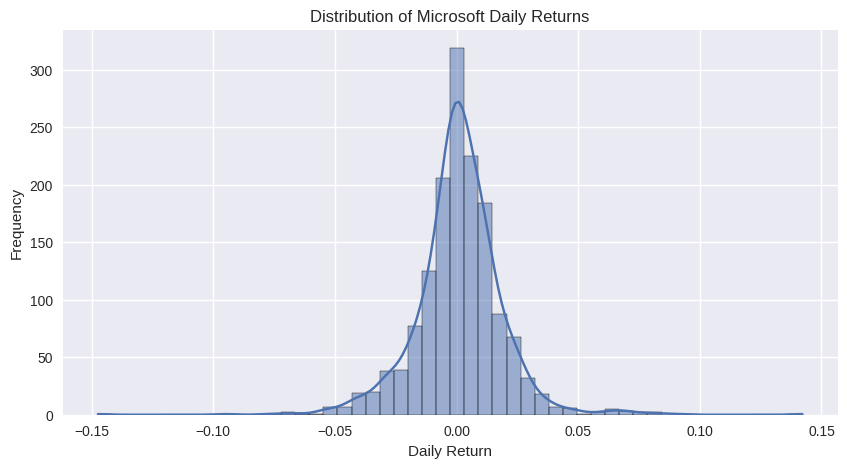

In [27]:
plt.figure(figsize=(10, 5))

sns.histplot(msft["Daily_Return"].dropna(), bins=50, kde=True)

plt.title("Distribution of Microsoft Daily Returns")
plt.xlabel("Daily Return")
plt.ylabel("Frequency")

plt.show()

In [28]:
msft["MA_30"] = msft["Close"].rolling(window=30).mean()

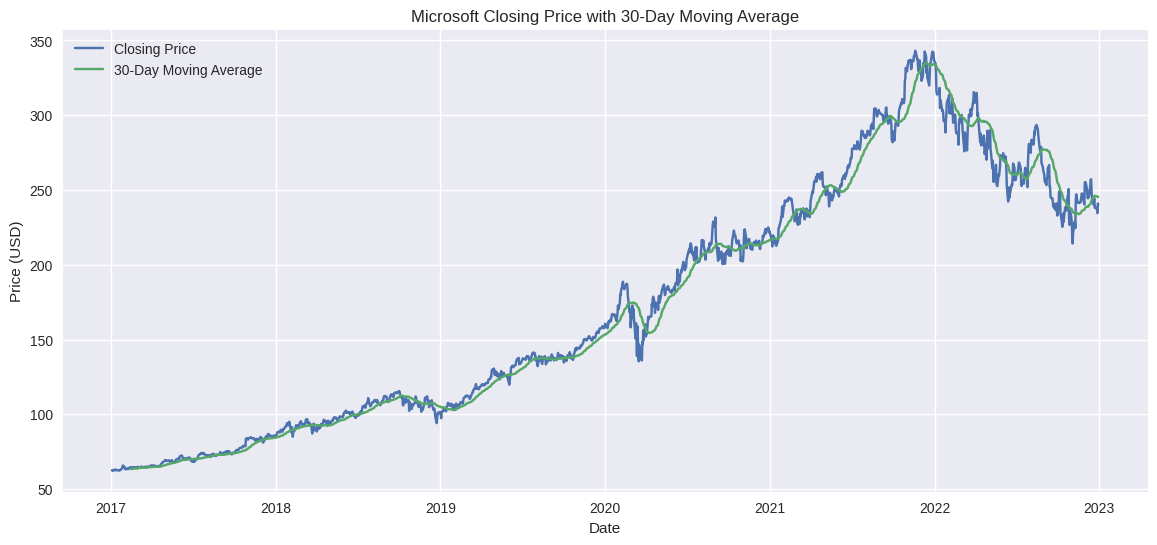

In [29]:
plt.figure(figsize=(14, 6))

plt.plot(msft.index, msft["Close"], label="Closing Price")
plt.plot(msft.index, msft["MA_30"], label="30-Day Moving Average")

plt.title("Microsoft Closing Price with 30-Day Moving Average")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True)

plt.show()

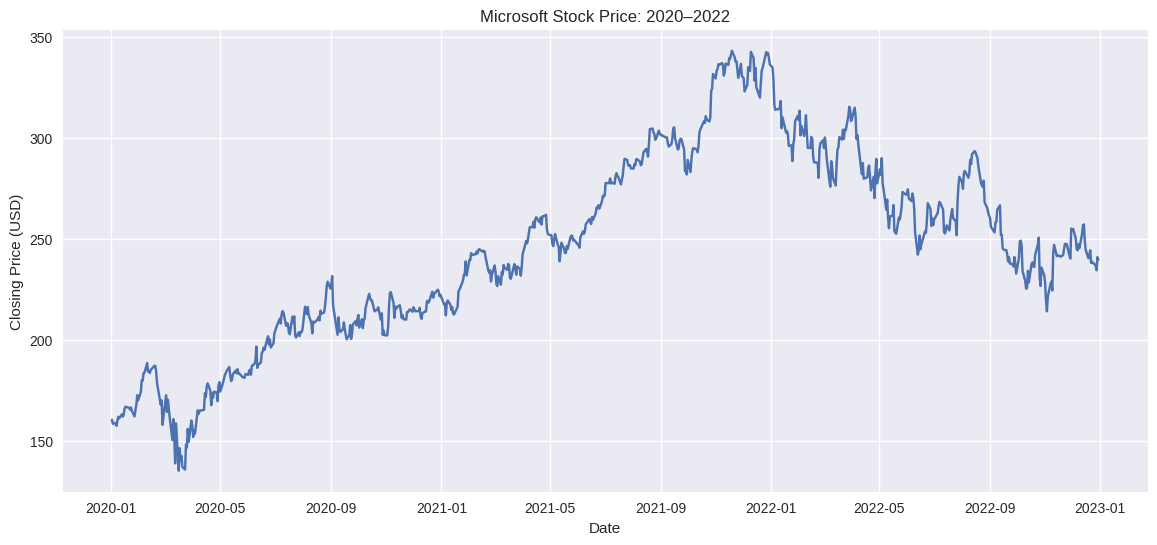

In [30]:
msft_2020_2022 = msft.loc["2020-01-01":"2022-12-31"]

plt.figure(figsize=(14, 6))

plt.plot(msft_2020_2022.index, msft_2020_2022["Close"])

plt.title("Microsoft Stock Price: 2020–2022")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.grid(True)

plt.show()

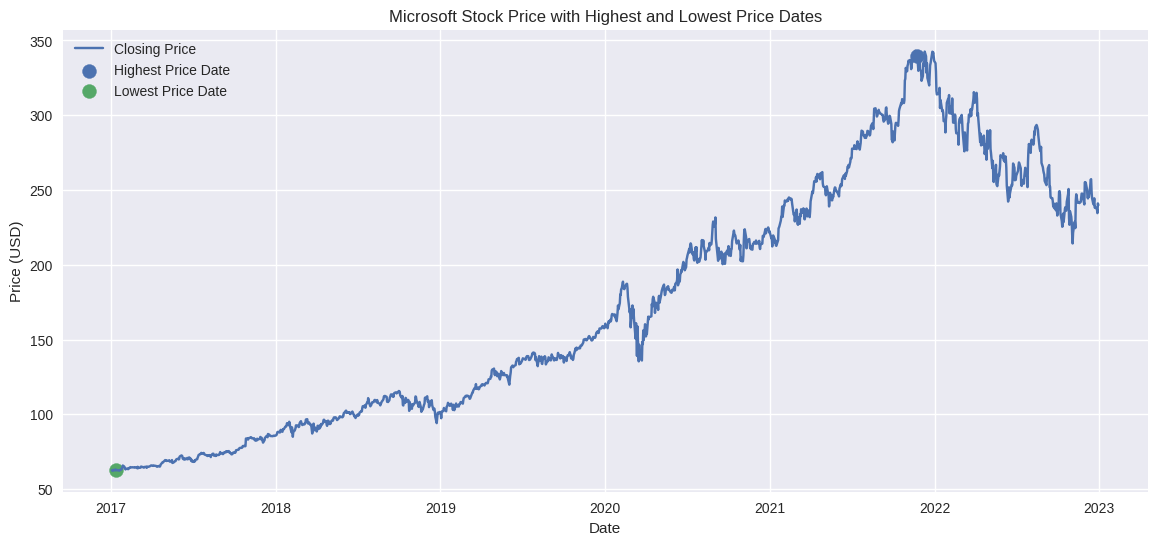

In [31]:
max_date = msft["High"].idxmax()
max_price = msft["High"].max()

min_date = msft["Low"].idxmin()
min_price = msft["Low"].min()

plt.figure(figsize=(14, 6))

plt.plot(msft.index, msft["Close"], label="Closing Price")

plt.scatter(max_date, msft.loc[max_date, "Close"], s=100, label="Highest Price Date")
plt.scatter(min_date, msft.loc[min_date, "Close"], s=100, label="Lowest Price Date")

plt.title("Microsoft Stock Price with Highest and Lowest Price Dates")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True)

plt.show()

In [32]:
highest_close = msft["Close"].max()
highest_close_date = msft["Close"].idxmax()

print("Highest Closing Price:", highest_close)
print("Date:", highest_close_date)

Highest Closing Price: 343.1099853515625
Date: 2021-11-19 00:00:00


In [33]:
lowest_close = msft["Close"].min()
lowest_close_date = msft["Close"].idxmin()

print("Lowest Closing Price:", lowest_close)
print("Date:", lowest_close_date)

Lowest Closing Price: 62.29999923706055
Date: 2017-01-04 00:00:00


In [34]:
import pandas_datareader.data as web

In [36]:
print("=" * 50)
print("MICROSOFT STOCK ANALYSIS (2017-2022)")
print("=" * 50)

print(f"Maximum High Price : ${msft['High'].max():.2f}")
print(f"Date of Highest    : {msft['High'].idxmax().date()}")

print(f"Minimum Low Price  : ${msft['Low'].min():.2f}")
print(f"Date of Lowest     : {msft['Low'].idxmin().date()}")

print("=" * 50)

MICROSOFT STOCK ANALYSIS (2017-2022)
Maximum High Price : $349.67
Date of Highest    : 2021-11-22
Minimum Low Price  : $61.95
Date of Lowest     : 2017-01-12


# Conclusion

In this project, Microsoft's (MSFT) historical stock data from 2017 to 2022 was analyzed using Python, Pandas, and time series exploratory data analysis techniques.

The analysis showed that the **maximum daily high price** of Microsoft stock during this period was **349.67 dollars** , which was recorded on **November 22, 2021**. The **minimum daily low price** was **$61.95**, recorded on **January 12, 2017**.

Time series visualizations were used to understand the movement of Microsoft's stock price over the selected period. The analysis also included daily closing prices, monthly price trends, daily returns, and a 30-day moving average.

Overall, the analysis shows that Microsoft's stock experienced significant growth between 2017 and 2022, along with periods of considerable price fluctuations. The use of Pandas and time series analysis made it easier to identify important price levels, trends, and changes in Microsoft's stock performance.
